# Demo 1: does age structure buy forecast skill?

Three influenza models over the full FluSight 2025-26 challenge period, identical but for
their contact structure.

| model | structure |
|---|---|
| `multi-strata-empirical` | six age strata, the Mistry et al. contact matrix |
| `multi-strata-homogeneous` | six age strata, contact in proportion to group size |
| `single-strata` | one population, no age structure |

**Hand-maintained.** There is no generator in `scratch/`; edit this directly. The loading,
scoring and figure code lives in `evaluation.py`, shared with the manuscript exporter so a
figure here and the same figure in the paper come from one function.

**Reading order.** Section 3 is provenance and completeness; read it before any score.
Section 5 carries a caveat that currently limits what can be claimed per jurisdiction.

## Setup

In [ ]:
# Pick up edits to the analysis package without restarting the kernel. Worth
# having: these modules are edited while this notebook is open, and a kernel holding a
# stale import fails with a confusing AttributeError on a function that is right there
# in the file. After changing the *shape* of `Evaluation` (not just a function body),
# re-run the load cell, since instances keep the class they were built with.
%load_ext autoreload
%autoreload 2

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from manuscript_analysis.demos import export, paths
from manuscript_analysis.demos.flu import evaluation as ev_mod
from manuscript_analysis.demos.flu.models import flu_season
from manuscript_analysis.demos.flu.seasons import seasons
from manuscript_analysis.demos.lib.figures import save_figure, use_manuscript_style

# The notebook's own figures, kept apart from the paper's. `results/figures/` holds
# only what `manuscript_analysis.demos.export` composes; these are the panels on
# their own, for reading. Disposable.
NOTEBOOK_FIGURES = paths.RESULTS / "demos" / "notebook"

use_manuscript_style()

SEASON = seasons["FLU2025"]
OUTPUT = paths.runs("flu", seed=0)

print(f"{SEASON.name}: simulated window opens {SEASON.start_date}, {SEASON.weeks} weeks")
print(f"  {SEASON.burn_in_weeks}-week burn-in, {SEASON.horizon_weeks}-week horizon")
print(f"  {len(SEASON.states)} jurisdictions forecast, {len(SEASON.scored_states)} scored")

## 1. Run the models

Each writes to `output/<model>/` and is skipped if a run with the *same* configuration is
already there. A changed season window, burn-in or seed forces a re-run rather than
silently reusing stale output. Safe to re-run: it does nothing if the outputs are current.

Each fit is single-threaded, so from a terminal run the three in parallel with `&`.

In [ ]:
from manuscript_analysis.demos.lib.cli import run_season_cli

SPECS = [
    "models.multi_strata_flu:empirical",
    "models.multi_strata_flu:homogeneous",
    "models.single_strata",
]

for spec in SPECS:
    run_season_cli(
        seasons,
        default_season="FLU2025",
        output_root=lambda seed: paths.runs("flu", seed=seed),
        package="manuscript_analysis.demos.flu",
        argv=[spec],
    )

## 2. Load and score

`observations.csv` is frozen: fetched once and shared by every model. The ADRIO reads CDC's
preliminary dataset, which is revised weekly, so re-deriving it would move the numbers under
the manuscript.

The scoring target is the **sum of the six age bands**, which is what all three models were
fitted on; the ADRIO's own all-ages figure differs by about 0.25% and is never fitted.

In [3]:
ev = ev_mod.load()

print(f"forecasts {ev.forecasts[ev_mod.MODELS[0]].shape} "
      f"(origins, horizons, jurisdictions, quantile levels)")
print(f"{len(ev.origins)} origins, {ev.origins[0]} to {ev.origins[-1]}")
print(f"horizons {list(ev.horizons)}, {len(ev.locations)} jurisdictions scored")
print("all models verified against an identical target")

forecasts (25, 4, 51, 5) (origins, horizons, jurisdictions, quantile levels)
25 origins, 2025-11-22T00:00:00.000000000 to 2026-05-09T00:00:00.000000000
horizons [0, 1, 2, 3], 51 jurisdictions scored
all models verified against an identical target


## 3. Provenance and completeness

In [4]:
provenance = pd.DataFrame([
    {
        "model": name,
        "season": run.info["season"],
        "window": f"{run.info['season_start']} +{run.info['season_weeks']}w",
        "R": run.info["num_realizations"],
        "burn-in": run.info["burn_in_weeks"],
        "horizon": run.info["horizon_weeks"],
        "seed": run.info["seed"],
        "minutes": round(run.info["elapsed_seconds"] / 60, 1),
        "quantities": len(run.info["quantities"]),
    }
    for name, run in ev.runs.items()
])
provenance

,model,season,window,R,burn-in,horizon,seed,minutes,quantities
0,multi-strata-empirical,FLU2025,2025-09-13 +38w,300,10,4,0,231.6,6
1,multi-strata-homogeneous,FLU2025,2025-09-13 +38w,300,10,4,0,191.5,6
2,single-strata,FLU2025,2025-09-13 +38w,300,10,4,0,23.7,1


In [5]:
# The models must differ ONLY in structure, or the comparison is not controlled.
must_match = ["season", "window", "R", "burn-in", "horizon", "seed"]
differing = [c for c in must_match if provenance[c].nunique() > 1]
assert not differing, f"models were not run identically: {differing}"
print(f"all {len(ev.runs)} models agree on {', '.join(must_match)}")
print("quantities differ by design:",
      dict(zip(provenance["model"], provenance["quantities"])))

all 3 models agree on season, window, R, burn-in, horizon, seed
quantities differ by design: {'multi-strata-empirical': 6, 'multi-strata-homogeneous': 6, 'single-strata': 1}


## 4. Forecast skill

In [6]:
ev_mod.wis_table(ev).round(3)

,WIS,h0,h1,h2,h3,rel WIS,cov95,cov50
multi-strata-empirical,117.540,45.253,100.302,149.711,174.895,0.833,0.767,0.335
multi-strata-homogeneous,156.992,54.913,125.201,198.469,249.384,1.112,0.737,0.330
single-strata,141.144,47.141,111.335,178.822,227.277,1.000,0.754,0.340


In [7]:
# Relative WIS by horizon. Pooled numbers hide the horizon structure entirely.
baseline = ev.scores[ev_mod.BASELINE].total.mean(axis=(0, 2))
pd.DataFrame(
    {f"h{h}": [ev.scores[m].total.mean(axis=(0, 2))[i] / baseline[i] for m in ev.scores]
     for i, h in enumerate(ev.horizons)},
    index=list(ev.scores),
).round(3)

,h0,h1,h2,h3
multi-strata-empirical,0.960,0.901,0.837,0.770
multi-strata-homogeneous,1.165,1.125,1.110,1.097
single-strata,1.000,1.000,1.000,1.000


## 5. The distribution across jurisdictions

Admissions scale with population, so a mean over jurisdictions is dominated by the four
largest and is a statement about those four dressed up as a national result. The paired
per-jurisdiction ratio is the stronger statistic.

**What is and is not reproducible (R = 300, seed 0 against seed 1 with the denominator
matched in both).** Every model is re-run at the second seed, never a seed-1 numerator
against a seed-0 baseline; see `sensitivity/README.md` for why that distinction cost two
earlier analyses their conclusions.

| | median ratio | wins | p |
|---|---|---|---|
| empirical, seed 0 | 0.811 | 47/51 | 2.4e-10 |
| empirical, seed 1 | 0.831 | 45/51 | 1.8e-08 |
| homogeneous, seed 0 | 1.024 | 22/51 | 0.40 |
| homogeneous, seed 1 | 0.969 | 30/51 | 0.26 |

The **aggregate is reproducible** for the empirical model: the median ratio stays near 0.82
and the win count near 46 of 51, overwhelmingly significant at both seeds. The
**per-jurisdiction assignment is not**: 8 jurisdictions change which model they favour
between seeds (AK, AL, DE, OR, SD, VT, WV, WY, all small), and the per-state ratios correlate
only 0.14 across seeds.

Think of it as 51 biased coins. The count is reproducible; which coins land heads is not.
The sign test is therefore still valid, and per-state noise costs power rather than validity.

So *"better in about 90% of jurisdictions"* and *"median ratio about 0.82"* are supportable.
*"better in Kansas"* is not. Read the figure below as a distribution, never as a per-state
result, and read the per-jurisdiction table the same way.

The homogeneous model is a different case: it is not distinguishable from no age structure
at all (26 of 51 jurisdictions flip between seeds, and neither seed is significant). That is
the finding, not a defect. The benefit comes from the contact data, not from stratifying.

In [8]:
from scipy.stats import binomtest

summary = []
for model in ev_mod.MODELS:
    if model == ev_mod.BASELINE:
        continue
    ratios = ev_mod.relative_by_state(ev, model)
    wins = int((ratios < 1).sum())
    summary.append({
        "model": model,
        "median ratio": np.median(ratios),
        "wins": f"{wins}/{len(ratios)}",
        "p (provisional)": binomtest(wins, len(ratios), 0.5).pvalue,
        "best": f"{ev.labels[ev.locations[ratios.argmin()]]} {ratios.min():.2f}",
        "worst": f"{ev.labels[ev.locations[ratios.argmax()]]} {ratios.max():.2f}",
    })
pd.DataFrame(summary).round(4)

,model,median ratio,wins,p (provisional),best,worst
0,multi-strata-empirical,0.8108,47/51,0.0000,WV 0.47,WY 2.81
1,multi-strata-homogeneous,1.0237,22/51,0.4011,IA 0.58,SD 2.06


In [9]:
# Every jurisdiction's mean WIS under each model, for the supplement.
# Sorted by the empirical ratio so the range is visible, but this is a reference table:
# the per-jurisdiction ORDER is not reproducible across seeds, only the distribution is.
by_jurisdiction = ev_mod.wis_by_jurisdiction(
    ev, sort_by=f"multi-strata-empirical / {ev_mod.BASELINE}"
)
by_jurisdiction.round(2)

,fips,multi-strata-empirical,multi-strata-homogeneous,single-strata,multi-strata-empirical / single-strata,multi-strata-homogeneous / single-strata
jurisdiction,,,,,,
WV,54,40.93,76.62,86.95,0.47,0.88
NE,31,35.73,74.45,67.65,0.53,1.10
DE,10,22.06,50.40,38.18,0.58,1.32
SD,46,35.58,116.88,56.84,0.63,2.06
MN,27,88.22,190.80,140.50,0.63,1.36
MA,25,105.41,132.05,159.49,0.66,0.83
VT,50,15.41,14.69,23.23,0.66,0.63
KS,20,86.78,186.13,129.01,0.67,1.44
MO,29,216.97,393.59,304.39,0.71,1.29


## 6. Manuscript figures

Panels of Figure 2 in `drafts/figure-plan-v01.md`. Every one comes from `evaluation.py`, so
the paper and this notebook cannot disagree. Colours are fixed paper-wide: the unstratified
baseline grey, added structure blue, deliberately degraded structure orange.

In [ ]:
# What the figures are drawn for. These live in `evaluation.py` because
# `manuscript_analysis.demos.export` needs the same answer: two copies of the choice is how the
# paper and this notebook end up showing different states. Edit them there to change
# the paper; assign over them in this cell for a one-off look.
FOCUS = ev_mod.FOCUS_STATE                  # the state every single-state panel draws
REFERENCE_STATES = ev_mod.REFERENCE_STATES  # the states the multi-state panels draw

print("focus:", FOCUS, " reference states:", REFERENCE_STATES)

# Figure 2(a): the contact structures the two stratified models actually use.
# Demo 2's opening panel is its commuting matrix; this is the counterpart, so panel (a)
# means the same thing in both figures.
#
# One shared colour scale, deliberately. Every matrix is normalized to unit spectral
# radius before a model sees it, so the two cannot differ in their leading eigenvalue,
# only in its eigenvector: the comparison tests the SHAPE of mixing and leaves overall
# transmissibility for q(t) to fit.
fig = ev_mod.figure_contact_structures(FOCUS)
save_figure(fig, "flu-contact-structures", figure_dir=NOTEBOOK_FIGURES)
plt.show()

1 extra bytes in post.stringData array
'created' timestamp seems very low; regarding as unix timestamp
1 extra bytes in post.stringData array
'created' timestamp seems very low; regarding as unix timestamp


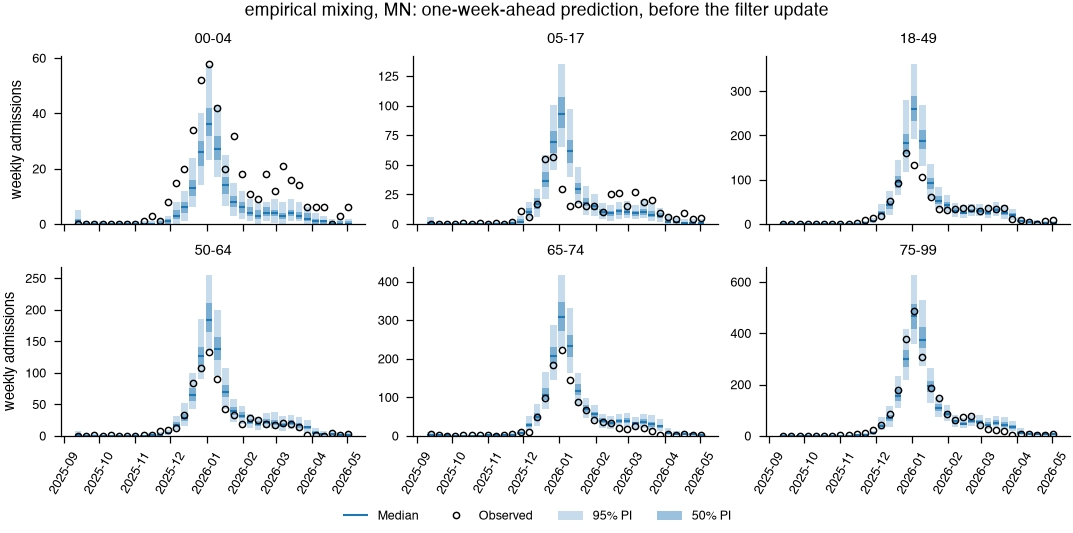

1 extra bytes in post.stringData array
'created' timestamp seems very low; regarding as unix timestamp
1 extra bytes in post.stringData array
'created' timestamp seems very low; regarding as unix timestamp


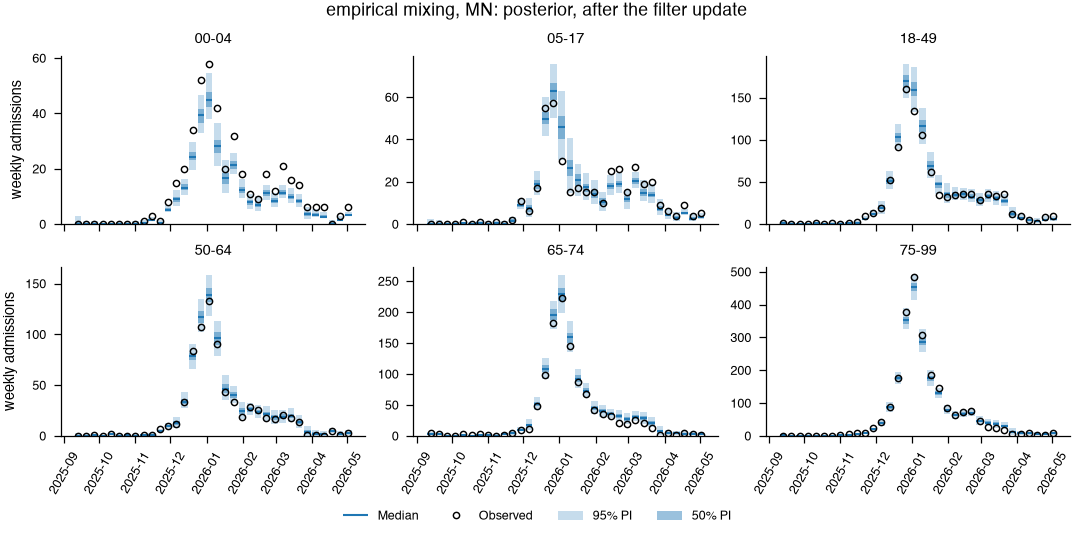

In [11]:
# SUPPLEMENTARY: the model fitting six channels rather than one.
# Six age bands over two rows of three, with the dates printed once, under the
# bottom row. Pass `ncols=6` for the single row this used to be.
# Demoted from Figure 2(a) when the contact matrices were promoted there, so that
# panel (a) means the same thing in Figures 2 and 3. It demonstrates *fitting*
# rather than *what varies*, and Box 1 already carries the code-level difference.
# The PRIOR is the one-week-ahead prediction before the Kalman update, so it is a genuine
# prediction; the posterior is pulled onto the observation by construction.
fig = ev_mod.figure_fit_by_age(ev, FOCUS, "multi-strata-empirical", series="prior")
save_figure(fig, "flu-fit-by-age-prior", figure_dir=NOTEBOOK_FIGURES)
plt.show()

# The posterior, for the supplement: the gap between the two is how hard the filter worked.
fig = ev_mod.figure_fit_by_age(ev, FOCUS, "multi-strata-empirical", series="posterior")
save_figure(fig, "flu-fit-by-age-posterior", figure_dir=NOTEBOOK_FIGURES)
plt.show()

1 extra bytes in post.stringData array
'created' timestamp seems very low; regarding as unix timestamp


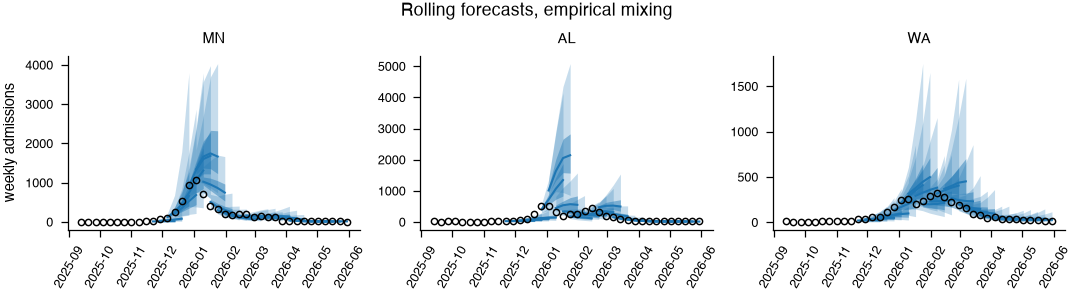

In [12]:
# Figure 2(b): every origin's forecast against the observed series.
# Every figure function takes `title`: a string of your own, or None for no title,
# which is what a panel of a composed multi-panel figure wants.
fig = ev_mod.figure_rolling_forecasts(
    ev, ev_mod.focus_states(ev), "multi-strata-empirical"
)
save_figure(fig, "flu-rolling-forecasts", figure_dir=NOTEBOOK_FIGURES)
plt.show()

1 extra bytes in post.stringData array
'created' timestamp seems very low; regarding as unix timestamp


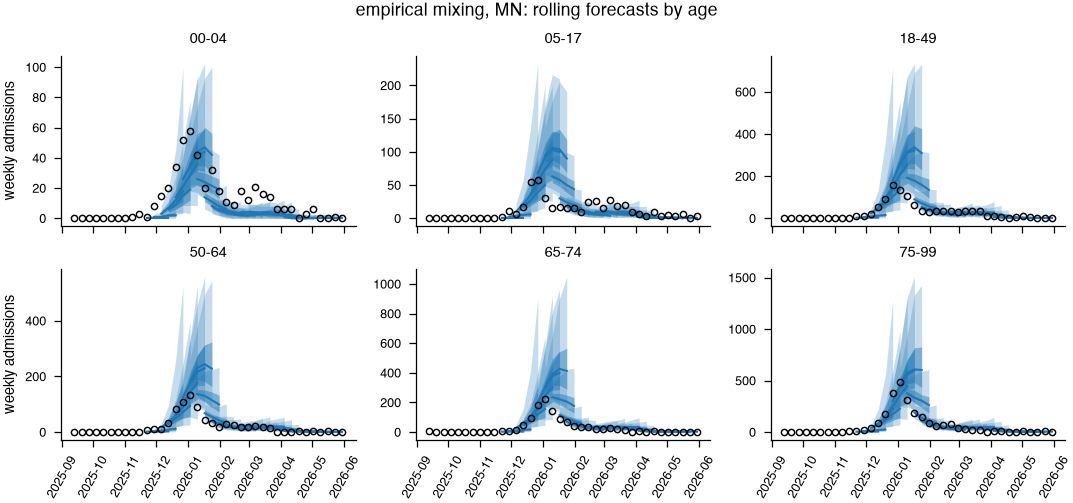

In [13]:
# Figure 2(b), age-resolved: where the scored total comes from. Change FOCUS to move state.
fig = ev_mod.figure_rolling_forecasts_by_age(ev, FOCUS, "multi-strata-empirical")
save_figure(fig, f"flu-rolling-by-age-{FOCUS}", figure_dir=NOTEBOOK_FIGURES)
plt.show()


1 extra bytes in post.stringData array
'created' timestamp seems very low; regarding as unix timestamp


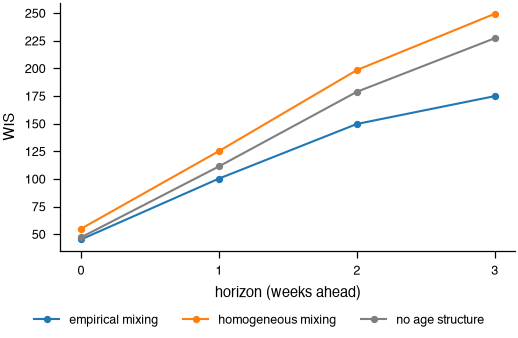

In [14]:
# Figure 2(c): skill against horizon.
fig = ev_mod.figure_wis_by_horizon(ev)
save_figure(fig, "flu-wis-by-horizon", figure_dir=NOTEBOOK_FIGURES)
plt.show()

1 extra bytes in post.stringData array
'created' timestamp seems very low; regarding as unix timestamp


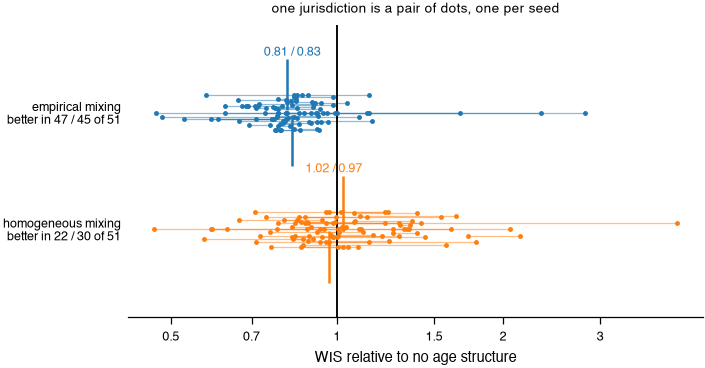

In [15]:
# Figure 2(d): both models' per-jurisdiction ratio against the baseline, two seeds each.
# The pair of dots is the point: per-jurisdiction ranking is not reproducible at R=300,
# and the jurisdictions whose dots are far apart are the ones not to read.
rep = ev_mod.load_replicate()
fig = ev_mod.figure_relative_wis_swarm(ev, rep)
save_figure(fig, "flu-relative-wis", figure_dir=NOTEBOOK_FIGURES)
plt.show()


### The composed figures

What `manuscript_analysis.demos.export` assembles the panels above into. Rendering them here is the
point of this section: a change to the focal states, the model, or any panel function
shows up in the actual deliverable rather than only in the panel.

| | Figure 2 | drawn by |
|---|---|---|
| (a) | contact structures | `figure_contact_structures` |
| (b) | WIS by horizon | `figure_wis_by_horizon` |
| (c) | the six age bands | `figure_fit_by_age` |
| (d) | per-jurisdiction WIS ratio | `figure_relative_wis_swarm` |

These cells display but do not write files. `python -m manuscript_analysis.demos.export` is what writes `figures/`.


In [ ]:
# `export_manuscript` contributes layout only; every panel is a function from this
# module. Built from the objects already loaded above, so nothing is re-fitted.
fig = export.figure_2_flu(ev, rep)
plt.show()


In [ ]:
# The supplementary forecast figure: the same forecasts at the model's own resolution
# (age bands, in the darker shade) and at the scale they are scored (state totals).
fig = export.figure_s_flu_forecasts(ev)
plt.show()


## 7. Calibration

Coverage against nominal, for the supplementary calibration figure. All three models are under-dispersed, which is an
honest limitation rather than something to bury.

1 extra bytes in post.stringData array
'created' timestamp seems very low; regarding as unix timestamp


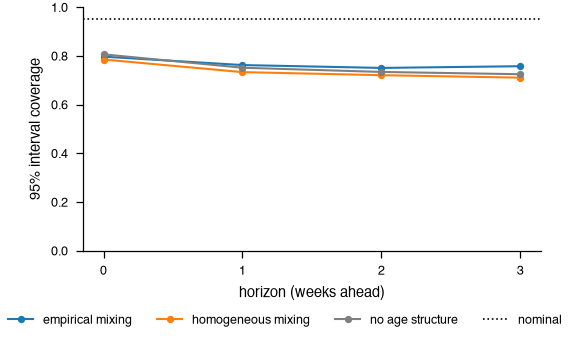

In [18]:
# Supplementary: coverage against nominal. Same function and same encoding as Demo 2's
# `figure_calibration`; Demo 1 scores one quantity, so it draws one panel.
fig = ev_mod.figure_calibration(ev, nominal=0.95)
save_figure(fig, "flu-calibration", figure_dir=NOTEBOOK_FIGURES)
plt.show()


## 8. The estimated parameters

`q(t)` is the shared transmissibility; `exp(eta_i)` is the per-age correction to the contact
matrix. Only differences between the `eta_i` are identified, since a common shift is
indistinguishable from a shift in `q(t)`, so they are centred at interpretation time rather
than constrained during estimation.

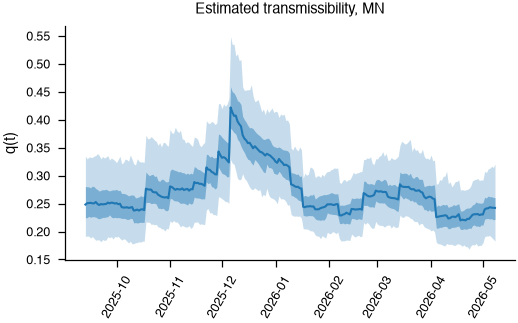

In [19]:
from demolib.plots import plot_quantile_bands
from demolib.results import quantile_array
from demolib.scoring import DEMO_QUANTILE_LEVELS

fips_of = {abbr: code for code, abbr in ev.labels.items()}
model = "multi-strata-empirical"
params = ev.runs[model].params
params = params[params["location"] == fips_of[FOCUS]]

q = params[params["parameter"].str.endswith("log_q")]
q_array, q_coords = quantile_array(q, ["date"], levels=DEMO_QUANTILE_LEVELS)

fig, ax = plt.subplots(figsize=(3.5, 2.2), layout="constrained")
plot_quantile_bands(
    ax, pd.to_datetime(q_coords["date"]),
    {lvl: np.exp(q_array[:, i]) for i, lvl in enumerate(DEMO_QUANTILE_LEVELS)},
    color=ev_mod.COLORS[model],
)
ax.set_ylabel("q(t)")
ax.set_title(f"Estimated transmissibility, {FOCUS}")
ax.tick_params(axis="x", labelrotation=60)
plt.show()

In [20]:
eta_names = sorted(n for n in params["parameter"].unique() if "log_eta" in n)
final = params[params["date"] == params["date"].max()]
medians = np.array([
    final[(final["parameter"] == n) & (np.isclose(final["quantile"], 0.5))]["value"].iloc[0]
    for n in eta_names
])
centred = medians - medians.mean()

print(f"{model}, {FOCUS}, week ending {pd.Timestamp(params['date'].max()).date()}")
print(f"{'band':>8}{'log eta':>10}{'centred':>10}{'factor':>9}")
for label, raw, c in zip(flu_season.STRATA_LABELS, medians, centred):
    print(f"{label:>8}{raw:>10.3f}{c:>10.3f}{np.exp(c):>9.3f}")
print(f"  ||eta|| (centred) = {np.linalg.norm(centred):.3f}")
print(f"  common component absorbed by q(t) = {medians.mean():+.3f}")

multi-strata-empirical, MN, week ending 2026-05-08
    band   log eta   centred   factor
   00-04     0.002     0.004    1.004
   05-17     0.004     0.005    1.005
   18-49     0.005     0.007    1.007
   50-64     0.008     0.009    1.009
   65-74    -0.014    -0.012    0.988
   75-99    -0.015    -0.013    0.987
  ||eta|| (centred) = 0.022
  common component absorbed by q(t) = -0.002


1 extra bytes in post.stringData array
'created' timestamp seems very low; regarding as unix timestamp


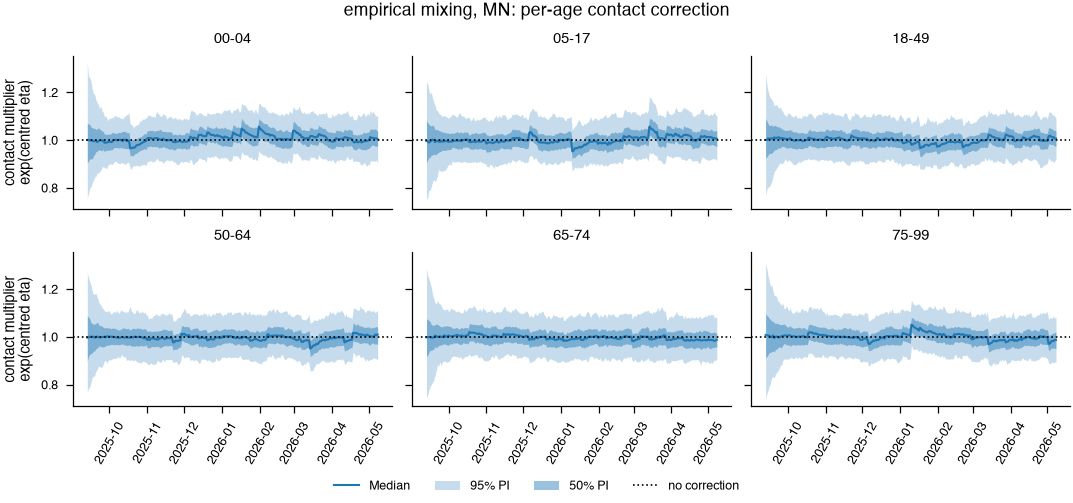

In [21]:
# The per-age contact correction through the season, not just its final value.
# Recentred per date by the mean of the six medians: a common shift is unidentified,
# being indistinguishable from a shift in q(t).
fig = ev_mod.figure_eta_by_age(ev, FOCUS, "multi-strata-empirical")
save_figure(fig, f"flu-eta-by-age-{FOCUS}", figure_dir=NOTEBOOK_FIGURES)
plt.show()


## 9. Summary

_Prose goes here once the sensitivity runs settle what can be claimed._